# Imputação e Normalização de Dados
Neste Jupyter, estarei realizando o diagnóstico estatístico para orientar minhas decisões a respeito do tratamento da base de anúncios de aluguel em São Paulo (imoveis_sao_paulo.csv). Estarei procurando por problemas de **lacunas**, variáveis que guardem valores em **diferentes métricas** e problemas de distribuição, como a existência de uma **cauda longa**.

Dessa forma, estarei usando, respectivamente, a **imputação**, para preencher dados perdidos ou inexistentes, o **escalonamento**, para normalizar as escalas numéricas e torná-las comparáveis, e também **transformações não lineares**, para alterar a geometria da distribuição e reduzir a assimetria dos dados.

In [1]:
#importando bibliotecas
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import (
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)
#configurando o estilo do seaborn
sns.set_theme(style="darkgrid", palette="pastel", font="Comic Sans MS") 

In [2]:
#importando o dataset de /data

df = pd.read_csv(Path("../data/imoveis_sao_paulo/imoveis_sao_paulo.csv"))
df.head()

,bairro,zona,tier,area,rooms,parking spaces,floor,total_floors,transit_distance_min,furniture,hoa (R$),rent amount (R$),property tax (R$),total (R$)
0,Santo Amaro,Zona Sul,mid,119.0,3,0.0,11.0,15.0,3,not furnished,NaN,5050.0,590.25,6910.0
1,Vila Mariana,Zona Sul,premium,97.9,3,1.0,15.0,25.0,10,not furnished,1072.0,5060.0,833.17,6970.0
2,Ipiranga,Zona Sul,mid,45.5,1,0.0,1.0,15.0,27,furnished,520.0,2470.0,283.92,3280.0
3,Raposo Tavares,Zona Oeste,mid,180.4,4,1.0,8.0,15.0,94,not furnished,2274.0,6270.0,775.17,9320.0
4,Brooklin,Zona Sul,luxury,36.1,0,1.0,2.0,8.0,1,not furnished,570.0,2960.0,330.00,3860.0


# 1. Primeiros Passos
Antes de começar a trabalhar na base, resolvo-me por renomear as variaveis (atributos da base) para português e remover duplicatas.

In [3]:
# Novos nomes para as colunas com espaços e símbolos
novos_nomes_colunas = {
    "parking spaces": "vagas_garagem",
    "hoa (R$)": "condominio_mensal",
    "rent amount (R$)": "aluguel_mensal",
    "property tax (R$)": "iptu_mensal",
    "rooms" : "quartos",
    "floor" : "andar",
    "total_floors" :"total_andares",
    "furniture" : "mobiliado",
    "total (R$)": "total",
    "transit_distance_min" : "distancia_centro_minutos"
}
#renmeando as colunas, removendo duplicatas e resetando o index
imoveis_df = (df.rename(columns = novos_nomes_colunas)
              .drop_duplicates()
              .reset_index(drop=True)
              )

imoveis_df.head()


,bairro,zona,tier,area,quartos,vagas_garagem,andar,total_andares,distancia_centro_minutos,mobiliado,condominio_mensal,aluguel_mensal,iptu_mensal,total
0,Santo Amaro,Zona Sul,mid,119.0,3,0.0,11.0,15.0,3,not furnished,NaN,5050.0,590.25,6910.0
1,Vila Mariana,Zona Sul,premium,97.9,3,1.0,15.0,25.0,10,not furnished,1072.0,5060.0,833.17,6970.0
2,Ipiranga,Zona Sul,mid,45.5,1,0.0,1.0,15.0,27,furnished,520.0,2470.0,283.92,3280.0
3,Raposo Tavares,Zona Oeste,mid,180.4,4,1.0,8.0,15.0,94,not furnished,2274.0,6270.0,775.17,9320.0
4,Brooklin,Zona Sul,luxury,36.1,0,1.0,2.0,8.0,1,not furnished,570.0,2960.0,330.00,3860.0


### 1.1 Novo atributo
Criei um novo atributo para distinguir entre casas (1 andar) e apartamentos (mais de 1 andar).

In [4]:
col_tipo_imoveis = np.where(imoveis_df["andar"].isnull(), "casa", "apartamento")
col_mobiliado = np.where(imoveis_df["mobiliado"].str.startswith("not"),"não", "sim") # renomeie a variavel mobiliado

imoveis_df["tipo_imovel"] = col_tipo_imoveis
imoveis_df["mobiliado"] = col_mobiliado
imoveis_df.head()

,bairro,zona,tier,area,quartos,vagas_garagem,andar,total_andares,distancia_centro_minutos,mobiliado,condominio_mensal,aluguel_mensal,iptu_mensal,total,tipo_imovel
0,Santo Amaro,Zona Sul,mid,119.0,3,0.0,11.0,15.0,3,não,NaN,5050.0,590.25,6910.0,apartamento
1,Vila Mariana,Zona Sul,premium,97.9,3,1.0,15.0,25.0,10,não,1072.0,5060.0,833.17,6970.0,apartamento
2,Ipiranga,Zona Sul,mid,45.5,1,0.0,1.0,15.0,27,sim,520.0,2470.0,283.92,3280.0,apartamento
3,Raposo Tavares,Zona Oeste,mid,180.4,4,1.0,8.0,15.0,94,não,2274.0,6270.0,775.17,9320.0,apartamento
4,Brooklin,Zona Sul,luxury,36.1,0,1.0,2.0,8.0,1,não,570.0,2960.0,330.00,3860.0,apartamento


## 1.2 Analise de Faltantes , Escalas e Distribuição
Na proxima etapa estarei analisando, quais atributos tem dados faltantes, suas proporções e tambem estarei analisando as escalas de alguns atributos numerios, assim como estarei plotando a distribuição para analisar seu formato e comportamento.

In [5]:
imoveis_df.isna().sum()

bairro                         0
zona                           0
tier                           0
area                           0
quartos                        0
vagas_garagem                297
andar                       4415
total_andares               4415
distancia_centro_minutos       0
mobiliado                      0
condominio_mensal            505
aluguel_mensal                 0
iptu_mensal                    0
total                          0
tipo_imovel                    0
dtype: int64

In [6]:
print("\n Faltantes :")
missing = (imoveis_df[["vagas_garagem","andar","condominio_mensal"]]
           .isna()
           .mean() #retorna a proporção nulos por count()
           .mul(100)
           )
print(missing)

print("\n Escalas :")
scales = imoveis_df[["vagas_garagem","andar","condominio_mensal"]].median()
print(scales)

print("\n Limit :")
limit = imoveis_df["aluguel_mensal"].quantile(0.985) # o valor abaixo do qual ficam 98% dos dados.
print(limit)




 Faltantes :
vagas_garagem         1.008866
andar                14.997113
condominio_mensal     1.715412
dtype: float64

 Escalas :
vagas_garagem          1.0
andar                  5.0
condominio_mensal    810.0
dtype: float64

 Limit :
15874.984000000002


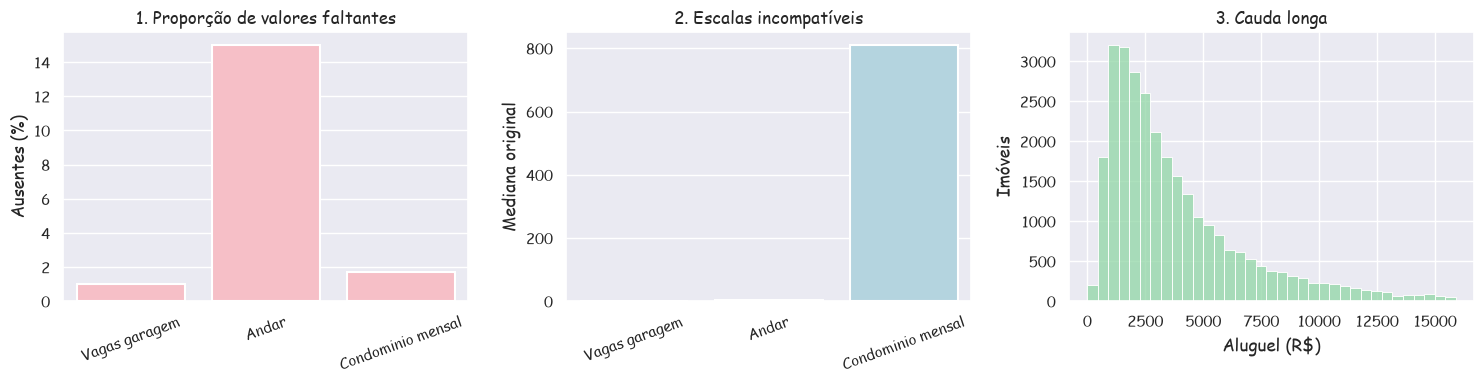

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4),)

#plot 1
sns.barplot(
    x=missing.index.astype(str).str.replace("_", " ").str.capitalize(),
    y=missing.values,
    ax=axes[0],
    color="lightpink",
    edgecolor="white", linewidth=1.5
)

axes[0].set(
    title = "1. Proporção de valores faltantes",
    ylabel = "Ausentes (%)",
    xlabel = ""
)
axes[0].tick_params(axis="x", rotation=20)

#plot 2
sns.barplot(
    x=scales.index.astype(str).str.replace("_", " ").str.capitalize(),
    y=scales.values,
    ax=axes[1],
    color="lightblue",
    edgecolor="white", 
    linewidth=1.5
)

axes[1].set(
    title = "2. Escalas incompatíveis",
    ylabel="Mediana original",
    xlabel=""
)
axes[1].tick_params(axis="x", rotation=20)


#plot 3
sns.histplot(
    imoveis_df["aluguel_mensal"],
    bins=35,
    binrange=(0, limit),#plota só até o threshold com o percentil 98%
    ax=axes[2],
    color="#91D6A6",
)

axes[2].set(
    title="3. Cauda longa",
    xlabel="Aluguel (R$)",
    ylabel="Imóveis",
)

plt.tight_layout()
plt.show()

**Valores ausentes:** condominio e vagas de garagem têm poucas lacunas (cerca de aproximadamente 2% e 1%), enquanto floor chega a 15%. Uma diferença tão grande sugere que a ausência em floor tem uma causa própria (casas tem andar como null?).

**Escalas incompatíveis:** O imóvel típico tem 2 quartos, cerca de 76 m² e aluguel de R$ 2.900. As três medianas estão separadas por ordens de grandeza, e o aluguel domina o painel apenas por causa da unidade.

**Cauda longa:** Três quartos dos aluguéis ficam abaixo de cerca de R$ 5.100, mas a cauda se estende muito à direita. O maior aluguel chega a quase R$ 38 mil, bem maior que o do recorte do gráfico.


# 2. Ausência estrutural
Agora que encontramos colunas com faltantes, precisamos analisar as condições de ausencia do valor, antes de escolher qualquer tecnica de imputação.
Na base de imóveis, **floor** e **total_floors** estão ausentes nas casas. Não houve falha de cadastro. Esses atributos descrevem a posição de uma unidade em um edifício e, portanto, não se aplicam a casas. Esse tipo de lacuna é chamado de ausência estrutural, pois decorre da definição da variável para determinado tipo de observação. Imputar um número produziria um valor sem referente real.

In [27]:
andar_por_tipo = (
                imoveis_df
                .assign(sem_andar = imoveis_df["andar"].isna()) # adiciona uma coluna de filtro
                .groupby("tipo_imovel")
                .agg(
                    quantidade=("tipo_imovel","count"),
                    proporcao_sem_andar = ("sem_andar","mean") # utiliza a coluna de filtro pra fazer a media
                    )
                )
andar_por_tipo.head()


,quantidade,proporcao_sem_andar
tipo_imovel,,
apartamento,25024,0.0
casa,4415,1.0


Corforme apontado e observado, os ausentes na realidade guardam uma informação importante sobre como o dataset distingue entre casas e apartamento

## 2.1 Sobre a imputação de valores ausentes

A imputação substitui valores ausentes por estimativas, usando estatísticas da própria coluna ou outras variáveis. Mesmo métodos simples podem concentrar artificialmente valores e reduzir a variabilidade dos dados.

Como não conhecemos os valores verdadeiros das lacunas reais, não é possível calcular diretamente o erro da imputação. Para avaliar os métodos, podemos simular esse cenário apagando valores de uma base completa, imputando-os e comparando os resultados com os valores originais.

Primeiro, implementamos uma função para apagar uma fração dos valores, mantendo a base completa como referência.


In [31]:
# Função de apagamento e base-gabarito
rng = np.random.default_rng(42)

def erase_at_random(values, share):
    return values.mask(rng.random(len(values)) < share)

imoveis_true = (
    imoveis_df
    .dropna(subset=["condominio_mensal", "vagas_garagem"])
    .reset_index(drop=True)
)
imoveis_true.head()

,bairro,zona,tier,area,quartos,vagas_garagem,andar,total_andares,distancia_centro_minutos,mobiliado,condominio_mensal,aluguel_mensal,iptu_mensal,total,tipo_imovel
0,Vila Mariana,Zona Sul,premium,97.9,3,1.0,15.0,25.0,10,não,1072.0,5060.0,833.17,6970.0,apartamento
1,Ipiranga,Zona Sul,mid,45.5,1,0.0,1.0,15.0,27,sim,520.0,2470.0,283.92,3280.0,apartamento
2,Raposo Tavares,Zona Oeste,mid,180.4,4,1.0,8.0,15.0,94,não,2274.0,6270.0,775.17,9320.0,apartamento
3,Brooklin,Zona Sul,luxury,36.1,0,1.0,2.0,8.0,1,não,570.0,2960.0,330.00,3860.0,apartamento
4,Itaquera,Zona Leste,affordable,97.3,3,1.0,6.0,15.0,2,não,1306.0,1370.0,222.75,2900.0,apartamento


Em seguida, criarei lacunas em três variáveis de tipos diferentes: discreta, contínua e categórica.

In [39]:
# Apaga valores em três colunas de tipos diferentes
imoveis_missing = (
    imoveis_true
    .assign(
        quartos=lambda df: erase_at_random(df["quartos"], .10),
        aluguel_mensal=lambda df: erase_at_random(df["aluguel_mensal"], .15),
        mobiliado=lambda df: erase_at_random(df["mobiliado"], .08),
    )
)

Conferimos quantos valores foram apagados:

In [48]:
tabela_proporção_ausentes = imoveis_missing[["quartos","aluguel_mensal","mobiliado"]].isna().sum().to_frame("ausentes")

tabela_proporção_ausentes["proporcao"] = (tabela_proporção_ausentes["ausentes"]/len(imoveis_missing)).round(2)

tabela_proporção_ausentes.head()

,ausentes,proporcao
quartos,2866,0.10
aluguel_mensal,4500,0.16
mobiliado,2261,0.08


# 2.2 Média, mediana e mediana agrupada
As estratégias mais simples substituem todas as lacunas por uma única constante calculada com os valores observados da coluna. 
A média utiliza toda a magnitude dos dados e, por isso, responde fortemente a valores extremos. 
A mediana depende apenas da ordenação e é mais resistente a caudas longas.


In [49]:
# Constantes para a imputação simples
rent_mean = (
    imoveis_missing.aluguel_mensal
    .mean()
)

rent_median = (
    imoveis_missing.aluguel_mensal
    .median()
)

A mediana por `tier` considera o padrão do imóvel para estimar os valores ausentes. Caso um grupo não tenha valores observados, utiliza-se a mediana global como alternativa.


In [ ]:
# Imputação pela mediana de cada tier
tier_based_median = (
                    imoveis_missing.
                    groupby("tier").
                    agg(mediana_por_tier = ("aluguel_mensal","median"))
                    )

mediana_da_linha = imoveis_missing["tier"].map(tier_based_median["mediana_por_tier"]) # coluna da mediana por tier de todas as tuplas

imoveis_input_por_tier = imoveis_missing.assign(aluguel_mensal=imoveis_missing["aluguel_mensal"].fillna(mediana_da_linha))

imoveis_input_por_tier.head(10)


,bairro,zona,tier,area,quartos,vagas_garagem,andar,total_andares,distancia_centro_minutos,mobiliado,condominio_mensal,aluguel_mensal,iptu_mensal,total,tipo_imovel
0,Vila Mariana,Zona Sul,premium,97.9,3.0,1.0,15.0,25.0,10,não,1072.0,5060.0,833.17,6970.0,apartamento
1,Ipiranga,Zona Sul,mid,45.5,1.0,0.0,1.0,15.0,27,sim,520.0,2470.0,283.92,3280.0,apartamento
2,Raposo Tavares,Zona Oeste,mid,180.4,4.0,1.0,8.0,15.0,94,não,2274.0,6270.0,775.17,9320.0,apartamento
3,Brooklin,Zona Sul,luxury,36.1,0.0,1.0,2.0,8.0,1,não,570.0,2960.0,330.00,3860.0,apartamento
4,Itaquera,Zona Leste,affordable,97.3,3.0,1.0,6.0,15.0,2,não,1306.0,1370.0,222.75,2900.0,apartamento
5,Brooklin,Zona Sul,luxury,56.0,NaN,2.0,10.0,15.0,0,não,1041.0,7360.0,476.50,4780.0,apartamento
6,Brooklin,Zona Sul,luxury,100.9,3.0,3.0,4.0,8.0,70,NaN,1331.0,7360.0,855.50,8270.0,apartamento
7,Limão,Zona Norte,mid,54.3,1.0,2.0,7.0,15.0,13,sim,642.0,1320.0,214.75,2180.0,apartamento
8,Jardim Europa,Zona Oeste,luxury,91.0,3.0,2.0,4.0,8.0,31,sim,883.0,7570.0,895.00,9340.0,apartamento
9,Guaianases,Zona Leste,affordable,45.4,1.0,0.0,1.0,4.0,50,não,470.0,750.0,100.58,1320.0,apartamento


Reunimos as versões do aluguel para compará-las lado a lado:

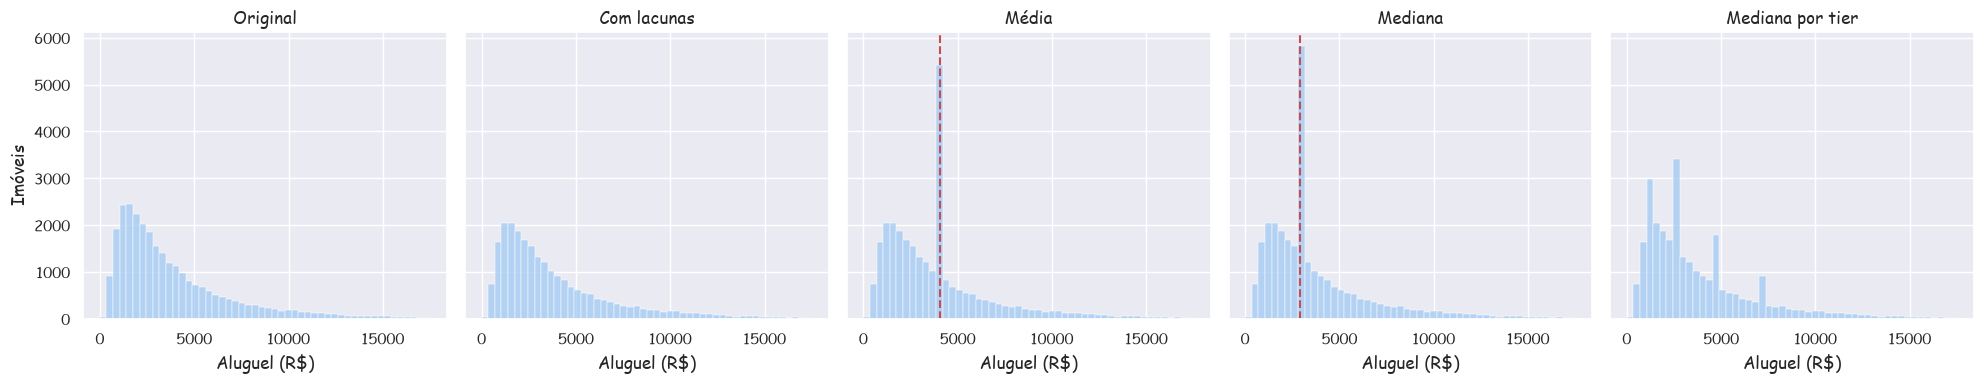

In [63]:
# Versões do aluguel a comparar
rent_versions = {
    "Original": imoveis_true.aluguel_mensal,
    "Com lacunas": imoveis_missing.aluguel_mensal,
    "Média": imoveis_missing.aluguel_mensal.fillna(rent_mean),
    "Mediana": imoveis_missing.aluguel_mensal.fillna(rent_median),
    "Mediana por tier": imoveis_input_por_tier.aluguel_mensal,
}

# Histograma de cada versão do aluguel
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

limit = imoveis_true.aluguel_mensal.quantile(.99)

for ax, (label, values) in zip(axes, rent_versions.items()):
    sns.histplot(
        values.dropna(),
        bins=50,
        binrange=(0, limit),
        ax=ax,
    )
    ax.set(
        title=label,
        xlabel="Aluguel (R$)",
        ylabel="Imóveis",
    )
    if label == "Média":
        ax.axvline(
            rent_mean,
            color="#C44E52",
            linestyle="--",
        )
    if label == "Mediana":
        ax.axvline(
            rent_median,
            color="#C44E52",
            linestyle="--",
        )

plt.tight_layout()
plt.show()

### 3.1.1 Erro absoluto médio (MAE)

Os histogramas mostram como a imputação altera a distribuição, mas não medem a precisão dos valores estimados. Como os valores apagados são conhecidos na base original, podemos comparar as estimativas com os valores verdadeiros.

O **MAE (*Mean Absolute Error*)** calcula a média dos erros absolutos, evitando que erros positivos e negativos se cancelem.

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

O resultado fica na mesma unidade da variável. Por exemplo, um MAE de R$ 500 indica que as estimativas erram, em média, R$ 500 em relação aos valores reais.
* **Considerar apenas os valores imputados** no cálculo do MAE; Afinal, incluir os valores observados reduziria artificialmente o erro.
* **A métrica favorece estratégias diferentes:** a mediana minimiza os erros absolutos, enquanto a média minimiza os erros quadráticos. Portanto, espera-se um MAE menor com a mediana, especialmente em distribuições assimétricas, como a dos aluguéis.

Primeiro, recuperamos no gabarito os valores verdadeiros das posições apagadas:


In [68]:
# Posições apagadas e seus valores verdadeiros
alugueis_faltantes = imoveis_missing.aluguel_mensal.isna()
aluguel_medio = rent_mean
aluguel_mediana = rent_median
aluguel_verdadeiro = imoveis_true.loc[alugueis_faltantes, "aluguel_mensal"]

In [69]:
# MAE de cada estratégia, apenas nas posições imputadas
(
    pd.Series(
        {
            "Média": (
                (aluguel_verdadeiro - aluguel_medio)
                .abs()
                .mean()
            ),
            "Mediana": (
                (aluguel_verdadeiro - aluguel_mediana)
                .abs()
                .mean()
            ),
            "Mediana por tier": (
                (aluguel_verdadeiro - imoveis_input_por_tier.loc[alugueis_faltantes, "aluguel_mensal"])
                .abs()
                .mean()
            ),
        },
        name="MAE (R$)",
    )
    .round(2)
    .to_frame()
)

,MAE (R$)
Média,2505.05
Mediana,2295.73
Mediana por tier,1772.37


Quanto menor o MAE, menor o erro médio das imputações. A mediana apresenta melhor resultado que a média, e a mediana por `tier` reduz ainda mais o erro ao considerar o padrão do imóvel. Essa avaliação vale para o cenário MCAR simulado, não garantindo o mesmo desempenho em dados com outros padrões de ausência.
